
## Lab 6 
**Regression Models in ML Systems: Linear Regression (OLS/Ridge/Lasso) and Logistic Regression (Probability, Thresholds, AUC)**

## Learning Objectives
By the end of this lab, you will be able to:
1. Implement reproducible splits and leakage-resistant pipelines for regression and classification.
2. Evaluate linear regression using RMSE and R² and interpret results.
3. Validate regression assumptions via residual diagnostics.
4. Detect multicollinearity using correlation and VIF.
5. Optimize generalization with Ridge/Lasso + cross-validation.
6. Train logistic regression for probabilistic classification.
7. Tune decision thresholds and justify precision/recall tradeoffs.
8. Propose production monitoring signals and identify leakage risks.

## Dataset
- **Primary:** House Prices (Ames Housing) via `sklearn.datasets.fetch_openml(name="house_prices", as_frame=True)`.
- **Fallback:** `fetch_california_housing()` (regression) and `load_breast_cancer()` (classification).

## Workflow Overview
1. Setup & reproducibility
2. Data acquisition
3. Data validation & profiling
4. Baseline linear regression (OLS) pipeline
5. Regression diagnostics + non-linearity check
6. Multicollinearity analysis (correlation + VIF)
7. Regularization (Ridge/Lasso CV)
8. Logistic regression + evaluation (AUC, confusion matrix)
9. Threshold tuning + ML systems reflection


**Note:** In this programming lab, you are required to execute all cells step by step and focus on understanding the methodology and the outcomes at each step. Answering the questions included in this lab (pre-coding and post-execution interpretation questions) is optional and is not required for the completion of the programming lab.

## Step 1 — Setup & reproducibility

### Coding questions
1. Why is `random_state` an ML-systems concern rather than a “cosmetic” parameter?      
The random_state argument controls the random operations such as data splitting into training and test sets. This feature is particularly useful for experiments' reproducibility and comparison since a randomized split can lead to different results for each iteration. Therefore, using the same random state allows getting similar results for the same train-test splits and comparing the models accurately. A different split of training and testing data can result in different conclusions about model performance.


2. What failure mode occurs if training data changes but you do not log dataset version and preprocessing parameters?   
It becomes more difficult to determine why the model changed. A newer version of the dataset or a different preprocessing could have made the model look better or worse even though nothing has changed in the model itself. Without this information it becomes much harder to reproduce the model and debug issues in production.


### Function/class selection + parameter exploration
- Explore: `numpy.random.seed`, `train_test_split` (`test_size`, `random_state`, `stratify`).
- In the notebook, run `help(train_test_split)` and identify at least 3 parameters that affect reproducibility or evaluation validity.


In [1]:
# Step 1: Setup & reproducibility
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print("Seed:", SEED)

# Parameter exploration prompt
help(train_test_split)


Seed: 42
Help on function train_test_split in module sklearn.model_selection._split:

train_test_split(
    *arrays,
    test_size=None,
    train_size=None,
    random_state=None,
    shuffle=True,
    stratify=None
)
    Split arrays or matrices into random train and test subsets.

    Quick utility that wraps input validation,
    ``next(ShuffleSplit().split(X, y))``, and application to input data
    into a single call for splitting (and optionally subsampling) data into a
    one-liner.

    Read more in the :ref:`User Guide <cross_validation>`.

    Parameters
    ----------
    *arrays : sequence of array-like of shape (n_samples,) or             (n_samples, n_outputs)
        Indexable data-structures can be arrays, lists, dataframes, scipy
        sparse matrices or pandas dataframes with consistent first dimension.

    test_size : float or int, default=None
        If float, should be between 0.0 and 1.0 and represent the proportion
        of the dataset to include in the t

### Execution interpretation questions
1. What evidence would you store to prove two students trained on the “same data” actually used the same rows?      
I would save the version or source of the data set, random seed, test_size, and the identifiers or indexes of the rows on training and testing sets. I would also save the preprocessing steps and the software versions. In addition, I would save a hash or checksum of the data set to have an additional guarantee that data was not altered.

2. If you cannot guarantee deterministic training (e.g., distributed training), what logs become essential?     
I would log the dataset version, training data identifiers, the preprocessing configuration, the model parameters, random seeds, the software versions, the hardware or compute environment, training time and the evaluation metrics. This would enable the investigation of differences even when exact reproducibility is not present.

## Step 2 — Data acquisition (real dataset) + basic inspection

### Pre-coding questions
1. Why does mixed-type data (numeric + categorical + missing values) increase pipeline risk in production?      
Numeric and categorical variables need different preprocessing approaches. Besides, missing data can occur unexpectedly when a model is exposed to new production data. Thus, if the pipeline is not prepared, the predictions will be faulty or have low confidence. The simplest solution to this problem is to create a pipeline that processes numerical and categorical data separately.

2. What is one way data acquisition can silently introduce leakage?     
Leakage can occur if information from the target or future data is accidentally included in the features. For example, a feature created using the final sale price would give the model information that would not be available when making a real prediction. Leakage can also occur when preprocessing statistics are calculated using the entire dataset before splitting.

### Function/class selection + parameter exploration
- Use: `fetch_openml(name=..., as_frame=...)`. Explore `name`, `version`, `as_frame`.
- Use: `DataFrame.info()`, `describe()`, `isna().mean()`.

In [2]:
# Step 2: Load Ames Housing from OpenML
housing = fetch_openml(name="house_prices", as_frame=True)
X_raw = housing.data.copy()
y_raw = housing.target.copy()

print("X shape:", X_raw.shape)
print("y shape:", y_raw.shape)
print("Target name:", getattr(y_raw, "name", "(unknown)"))
X_raw.head()


X shape: (1460, 80)
y shape: (1460,)
Target name: SalePrice


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1,60,RL,65.000,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.000,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,"2,003.000",RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal
1,2,20,RL,80.000,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,None,0.000,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,"1,976.000",RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal
2,3,60,RL,68.000,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.000,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,"2,001.000",RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal
3,4,70,RL,60.000,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,'Wd Sdng','Wd Shng',None,0.000,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,"1,998.000",Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml
4,5,60,RL,84.000,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.000,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,"2,000.000",RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal


In [3]:
# Quick inspection
print("\n--- Types (top) ---")
print(X_raw.dtypes.value_counts())

print("\n--- Missingness (top 15) ---")
missing_rate = X_raw.isna().mean().sort_values(ascending=False)
print(missing_rate.head(15))

print("\n--- Target summary ---")
y = pd.to_numeric(y_raw, errors="coerce")
print(y.describe())



--- Types (top) ---
object     43
int64      34
float64     3
Name: count, dtype: int64

--- Missingness (top 15) ---
PoolQC         0.995
MiscFeature    0.963
Alley          0.938
Fence          0.808
FireplaceQu    0.473
LotFrontage    0.177
GarageType     0.055
GarageYrBlt    0.055
GarageQual     0.055
GarageFinish   0.055
GarageCond     0.055
BsmtFinType2   0.026
BsmtExposure   0.026
BsmtCond       0.025
BsmtQual       0.025
dtype: float64

--- Target summary ---
count     1,460.000
mean    180,921.196
std      79,442.503
min      34,900.000
25%     129,975.000
50%     163,000.000
75%     214,000.000
max     755,000.000
Name: SalePrice, dtype: float64


In [4]:
# Requirement: >=3 numeric and >=1 categorical
candidate_features = [
    "LotArea",       # numeric
    "YearBuilt",     # numeric
    "GrLivArea",     # numeric
    "MSZoning",      # categorical
    "OverallQual"    # numeric
]
print("Candidate features:", candidate_features)

Candidate features: ['LotArea', 'YearBuilt', 'GrLivArea', 'MSZoning', 'OverallQual']


### Execution interpretation questions
1. Which variables have high missingness risk? How might that affect serving-time reliability?      
Variables containing a significant amount of missing information are more likely to lead to model errors when new production observations are acquired. If the pattern of missingness differs between training data and new observations the algorithm may fail to produce accurate predictions. The pipeline should therefore include an adequate imputation strategy and monitoring of missingness rates after deployment.

2. Which feature(s) could be proxies for sensitive attributes, and how would you audit?     
Features related to location, neighborhood, zoning, property type, or other demographic associated characteristics could potentially act as proxies for sensitive attributes. I would audit these features by examining their relationship with protected groups where that information is legally and appropriately available. I would also compare model errors and prediction distributions across relevant groups.

## Step 3 — Data validation & profiling (schema checks)

### Coding questions
1. What failure modes occur if a categorical feature introduces unseen levels at inference time?        
A categorical encoder may fail when it encounters a category that was not present during training. This can cause prediction errors and make the model unavailable for those observations. Using OneHotEncoder(handle_unknown="ignore") allows the pipeline to handle previously unseen categories without crashing.

2. What is the difference between data validation and model evaluation in an ML system?     
Data validation is the process of checking if the input data has the correct structure, types, ranges, missing values, and other quality control aspects. Model evaluation, on the other hand, is the process of testing the quality of the model’s output on the selected data set using such metrics as RMSE, R squared, accuracy, or AUC. The two concepts are different because data validation checks the quality of input data, whereas model evaluation checks the quality of the model’s results.

### Function/class selection and parameter exploration
- Use: simple custom checks (ranges, missingness thresholds).
- Later, ensure `OneHotEncoder(handle_unknown="ignore")` for robustness.

In [5]:
# Step 3: Minimal schema profile for selected features
assert len(candidate_features) > 0, "Choose candidate_features in TODO 1 first."

df = X_raw[candidate_features].copy()
df["SalePrice"] = y

print("Rows before dropping missing target:", df.shape[0])
df = df.dropna(subset=["SalePrice"]).copy()
print("Rows after dropping missing target:", df.shape[0])

print("\n--- Selected feature missingness ---")
print(df[candidate_features].isna().mean().sort_values(ascending=False))

print("\n--- Selected feature dtypes ---")
print(df[candidate_features].dtypes)


Rows before dropping missing target: 1460
Rows after dropping missing target: 1460

--- Selected feature missingness ---
LotArea       0.000
YearBuilt     0.000
GrLivArea     0.000
MSZoning      0.000
OverallQual   0.000
dtype: float64

--- Selected feature dtypes ---
LotArea         int64
YearBuilt       int64
GrLivArea       int64
MSZoning       object
OverallQual     int64
dtype: object


In [6]:
# Optional standalone gate check (safe to run independently)
# Recompute missing_gate in this cell so execution order doesn't matter.
missing_gate = df[candidate_features].isna().mean()
if (missing_gate > 0.40).any():
    bad = missing_gate[missing_gate > 0.40]
    raise ValueError(f"Missingness gate failed: {bad.to_dict()}")

print("Passed missingness gate.")

Passed missingness gate.


### Execution interpretation questions
1. In production, would you block predictions when the gate fails? When might you degrade gracefully instead?   
I would block predictions when the data failure could make the predictions unsafe or clearly invalid. For less severe problems, I might degrade gracefully by using an imputation strategy or a fallback model. The decision should depend on the severity of the data-quality issue and the potential impact of an incorrect prediction.

2. Where could leakage occur if you compute statistics (like medians) using the full dataset?       
Leakage occurs because the statistics would include information from the test set before the model is evaluated. For example, calculating the median using both training and test observations gives the training process information about the test distribution. The correct approach is to calculate preprocessing statistics using only the training data through a pipeline.

## Step 4 — Baseline linear regression (OLS) with leakage

### Coding questions
1. Why is it dangerous to one-hot encode before splitting the dataset?      
Encoding the categories before splitting can allow information from the full dataset to influence the preprocessing step. More importantly, doing preprocessing outside the training pipeline can create inconsistencies between training and inference. Using a ColumnTransformer and Pipeline ensures that preprocessing is learned from the training data and applied consistently to the test data and future observations.

2. What tradeoff exists between model simplicity (OLS) and robustness (regularization)?     
OLS is simple to understand and use, but can be unstable in the presence of multicollinearity or overfit when there are many correlated features. Ridge and Lasso regression add a regularization term to control for coefficient size and prevent overfitting, but introduce additional tuning parameters and complicate interpretation.

### Function/class selection and parameter exploration
- Use: `ColumnTransformer`, `Pipeline`, `OneHotEncoder(handle_unknown="ignore")`, `SimpleImputer`, `LinearRegression`.
- Explore: `LinearRegression(fit_intercept=...)` and explain what changes if `fit_intercept=False`.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Identify numeric vs categorical among the chosen predictors
num_features = df[candidate_features].select_dtypes(include=["number"]).columns.tolist()
cat_features = [c for c in candidate_features if c not in num_features]

print("Numeric:", num_features)
print("Categorical:", cat_features)

X = df[candidate_features]
y = df["SalePrice"].astype(float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

numeric_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
])

categorical_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_pipe, num_features),
        ("cat", categorical_pipe, cat_features),
    ],
    remainder="drop"
)

ols_model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", LinearRegression())
])

ols_model.fit(X_train, y_train)
y_pred = ols_model.predict(X_test)

# Compute RMSE in a version-safe way (older sklearn may not support squared=False).
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(f"OLS baseline RMSE: {rmse:,.2f}")
print(f"OLS baseline R^2 : {r2:.3f}")


Numeric: ['LotArea', 'YearBuilt', 'GrLivArea', 'OverallQual']
Categorical: ['MSZoning']
OLS baseline RMSE: 41,834.89
OLS baseline R^2 : 0.772


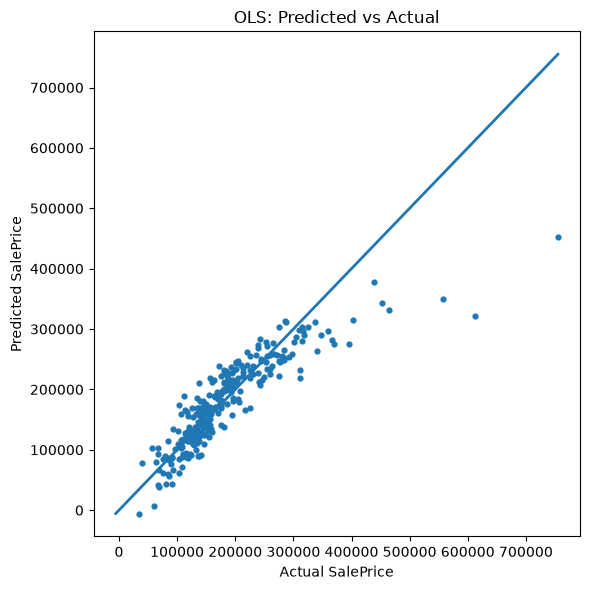

In [8]:
# Visualization: predicted vs actual
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, s=12)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, linewidth=2)
plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("OLS: Predicted vs Actual")
plt.tight_layout()
plt.show()


### Execution interpretation questions
1. If RMSE is large but R² is also high, what could both be telling you?        
A high R^2 means the model explains a large proportion of the variation in SalePrice compared with a simple mean-based prediction. A large RMSE can still occur when the target values have a large numerical scale, such as house prices. This means the model can explain the overall variation reasonably well while still making substantial errors in dollars.

2. What is one inference-time cost introduced by one-hot encoding?      
One-hot encoding can greatly increase the number of features. The model must process these additional columns for every prediction, which increases memory usage and can increase computation time. The effect is especially important when categorical variables have many unique values.

3. Identify one logging signal you would store per prediction in production.        
I would log the model version and prediction value for each prediction. I would also record a timestamp and relevant prediction or request identifiers where appropriate. For a regression model, the predicted SalePrice and input-data quality indicators would be useful for monitoring.

## Step 5 — Regression diagnostics: residuals, Q–Q, and a controlled non-linearity check

### Coding questions
1. What residual pattern would suggest heteroscedasticity? What systems risk does that create?      
A funnel-shaped pattern in the residuals versus fitted values would suggest heteroscedasticity. This means the size of the prediction errors changes depending on the predicted value. In production, this can cause the model to be much less reliable for certain ranges of predictions even if the overall RMSE looks acceptable.

2. If you see curvature in residuals vs fitted, what model change would you try first—and why?      
I would first try adding a simple non-linear feature, such as the quadratic GrLivArea_sq feature used in this lab. This is a controlled way to allow the model to capture curvature without immediately switching to a much more complex model. It can show whether a simple non-linear relationship improves prediction.

### Function/class selection and parameter exploration
- Use: `scipy.stats.probplot` for Q–Q.
- Introduce a simple quadratic term as a controlled non-linearity check.

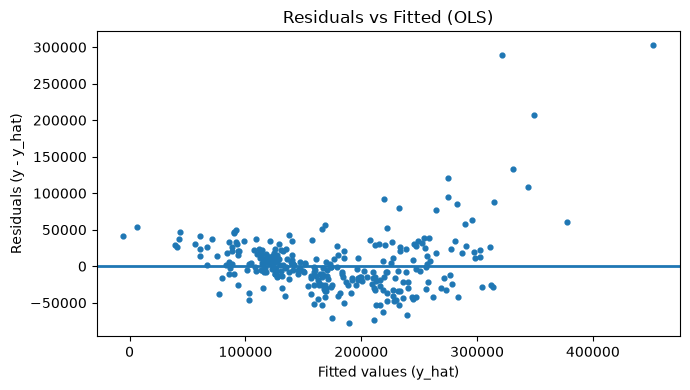

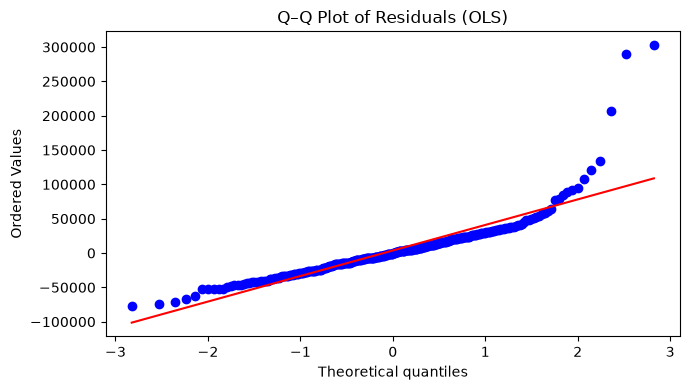

In [9]:
from scipy import stats

residuals = y_test - y_pred

plt.figure(figsize=(7, 4))
plt.scatter(y_pred, residuals, s=12)
plt.axhline(0, linewidth=2)
plt.xlabel("Fitted values (y_hat)")
plt.ylabel("Residuals (y - y_hat)")
plt.title("Residuals vs Fitted (OLS)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q–Q Plot of Residuals (OLS)")
plt.tight_layout()
plt.show()


In [10]:
X_nl = X.copy()

# Add one controlled non-linear term for a high-impact size feature.
X_nl["GrLivArea_sq"] = X_nl["GrLivArea"] ** 2

X_train_nl, X_test_nl, y_train_nl, y_test_nl = train_test_split(
    X_nl, y, test_size=0.2, random_state=SEED
)

num_features_nl = X_nl.select_dtypes(include=["number"]).columns.tolist()
cat_features_nl = [c for c in X_nl.columns if c not in num_features_nl]

preprocess_nl = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), num_features_nl),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_features_nl),
    ]
)

ols_nl = Pipeline(steps=[("preprocess", preprocess_nl), ("model", LinearRegression())])
ols_nl.fit(X_train_nl, y_train_nl)
y_pred_nl = ols_nl.predict(X_test_nl)

# Same RMSE formula for compatibility across sklearn versions.
rmse_nl = np.sqrt(mean_squared_error(y_test_nl, y_pred_nl))
r2_nl = r2_score(y_test_nl, y_pred_nl)

print(f"Non-linear feature RMSE: {rmse_nl:,.2f}")
print(f"Non-linear feature R^2 : {r2_nl:.3f}")

Non-linear feature RMSE: 50,682.20
Non-linear feature R^2 : 0.665


### Post-execution interpretation questions
1. If RMSE improves but residual normality worsens, would you adopt the change? Why/why not?    
The answer would depend on the goal of the model. If the main goal is prediction accuracy, then probably, the lower RMSE score would justify adopting the change. Otherwise, if there is a need in statistical inference and p-values, then probably, not, since the change made the residuals less normal.

2. Which diagnostic is most relevant if you care about inference validity (p-values) rather than pure prediction?   
The residual diagnostics are especially important, including the residual versus fitted plot and Q-Q plot. These plots help evaluate the homogeneity of variance and normal distribution of residuals, which are critical to statistical inference but less relevant to prediction.

3. ML Systems: what monitoring would detect the non-linear feature drifting out of range?   
I would check distribution of GrLivArea and GrLivArea_sq features through time. Compare current min, max, mean, percentiles, outlier rates to the training set distribution. Significant shift towards higher values would suggest that production set has observations far from training set in terms of living area, which would affect model performance.

## Step 6 — Multicollinearity analysis (correlation + VIF)

### Coding questions    
1. Why does multicollinearity harm coefficient interpretability even if test RMSE looks fine?       
Multicollinearity means that multiple predictors contain similar information. The model can still make accurate predictions, but the individual coefficients may become unstable or change substantially between different training samples. This makes it harder to determine the individual effect of each predictor.

2. In a business setting, when would you still keep correlated predictors?      
I would keep correlated predictors when they provide useful information for prediction and removing one would reduce model performance or remove an important business signal. If interpretability is less important than prediction accuracy, keeping both may be reasonable. Regularization can also help control the effects of correlated predictors.

### Function/class selection and parameter exploration
- Use: correlation among numeric features.

- Use: VIF (Variance Inflation Factor) to quantify multicollinearity.

             LotArea  YearBuilt  GrLivArea  OverallQual
LotArea        1.000      0.014      0.263        0.106
YearBuilt      0.014      1.000      0.199        0.572
GrLivArea      0.263      0.199      1.000        0.593
OverallQual    0.106      0.572      0.593        1.000


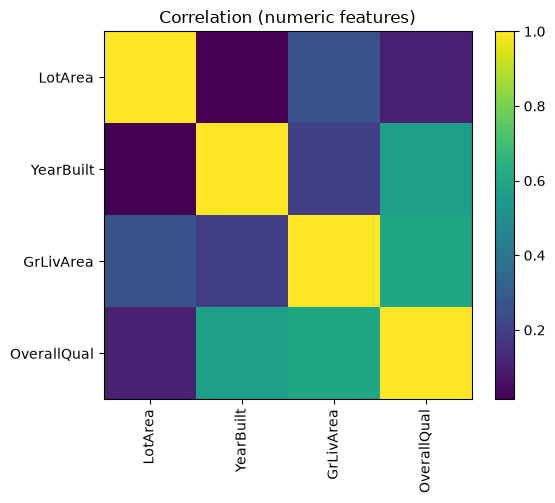

In [11]:
# Correlations among numeric features
num_df = df[num_features].copy()
corr = num_df.corr(numeric_only=True)
print(corr)

plt.figure(figsize=(6, 5))
plt.imshow(corr.values)
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation (numeric features)")
plt.colorbar()
plt.tight_layout()
plt.show()


In [12]:
# VIF computation (numeric features only)
# Some environments have statsmodels version conflicts; use fallback if import fails.
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score


def compute_vif_fallback(X_numeric):
    vif_rows_local = []
    cols = list(X_numeric.columns)

    for col in cols:
        y_col = X_numeric[col]
        X_others = X_numeric.drop(columns=[col])

        # If there is only one feature, VIF is 1 by definition.
        if X_others.shape[1] == 0:
            vif_rows_local.append({"feature": col, "VIF": 1.0})
            continue

        lr = LinearRegression()
        lr.fit(X_others, y_col)
        y_hat = lr.predict(X_others)
        r2 = r2_score(y_col, y_hat)

        # Guard against numerical edge cases when r2 is ~1.
        denom = max(1e-12, 1.0 - r2)
        vif_rows_local.append({"feature": col, "VIF": float(1.0 / denom)})

    return pd.DataFrame(vif_rows_local)


num_imputed = num_df.fillna(num_df.median(numeric_only=True)).astype(float)

try:
    import statsmodels.api as sm
    from statsmodels.stats.outliers_influence import variance_inflation_factor

    X_vif = sm.add_constant(num_imputed)
    vif_rows = []
    for i in range(1, X_vif.shape[1]):
        vif_rows.append({
            "feature": X_vif.columns[i],
            "VIF": float(variance_inflation_factor(X_vif.values, i)),
        })
    vif_table = pd.DataFrame(vif_rows)
except Exception as e:
    print(f"statsmodels unavailable/incompatible ({e}); using fallback VIF computation.")
    vif_table = compute_vif_fallback(num_imputed)

vif_table = vif_table.sort_values("VIF", ascending=False)
vif_table


,feature,VIF
3,OverallQual,2.313
2,GrLivArea,1.718
1,YearBuilt,1.558
0,LotArea,1.079


In [13]:
# Check if any VIF exceeds the threshold (commonly 5)
high_vif = vif_table[vif_table["VIF"] > 5]

if not high_vif.empty:
    # Option (b): keep all features but plan to use Ridge/Lasso regularization
    # Document the decision rationale
    print(
        "Some features have VIF > 5, indicating multicollinearity. "
        "Instead of dropping features (which could remove useful information), "
        "I will keep all features but use regularized regression methods such as Ridge or Lasso, "
        "which are robust to multicollinearity because they penalize large coefficients."
    )
else:
    print("No VIF > 5 detected, so no mitigation is needed.")

No VIF > 5 detected, so no mitigation is needed.


### Execution interpretation questions
1. If VIF is high, what might you observe in coefficient estimates across different train/test splits?      
The coefficients may change significantly between different splits even when the overall model performance remains similar. A coefficient may become larger, smaller, or even change sign because the model has difficulty separating the effects of correlated predictors.

2. ML Systems: how could multicollinearity interact with drift monitoring?      
When features are highly correlated, a change in one feature may be accompanied by changes in other features. This can make it harder to determine whether the model is responding to genuine drift or simply a change in the relationship between correlated variables. Monitoring both individual feature distributions and important feature relationships can help identify this problem.

## Step 7 — Regularization and cross-validation (Ridge/Lasso)


### Coding questions
1. Why can regularization improve test performance even if training error increases?        
Regularization penalizes overly large coefficients and reduces model complexity. This can increase training error slightly while reducing overfitting. The result can be better performance on unseen test data.

2. What tradeoff do you introduce when choosing Lasso vs Ridge?     
Ridge shrinks coefficients toward zero but usually keeps all features in the model. Lasso can shrink some coefficients completely to zero, which performs a form of feature selection. Ridge can be more stable when many predictors are correlated, while Lasso can produce a simpler model when sparse feature selection is useful.

### Function/class selection + parameter exploration
- Use: `RidgeCV`, `LassoCV`, and explain `alpha`.
- Explain why scaling matters for regularization.

In [14]:
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler

# Add scaling for numeric features (common for regularization)
numeric_pipe_scaled = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

preprocess_scaled = ColumnTransformer(
    transformers=[
        ("num", numeric_pipe_scaled, num_features),
        ("cat", categorical_pipe, cat_features),
    ],
    remainder="drop"
)

alphas = np.logspace(-3, 3, 25)

ridge = Pipeline(steps=[
    ("preprocess", preprocess_scaled),
    ("model", RidgeCV(alphas=alphas))
])

lasso = Pipeline(steps=[
    ("preprocess", preprocess_scaled),
    ("model", LassoCV(alphas=alphas, max_iter=50_000, random_state=SEED))
])

ridge.fit(X_train, y_train)
lasso.fit(X_train, y_train)

ridge_pred = ridge.predict(X_test)
lasso_pred = lasso.predict(X_test)

# Keep RMSE computation consistent and backward-compatible.
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_pred))

print("Ridge chosen alpha:", ridge.named_steps["model"].alpha_)
print("Lasso chosen alpha:", lasso.named_steps["model"].alpha_)
print(f"Ridge RMSE: {ridge_rmse:,.2f}")
print(f"Lasso RMSE: {lasso_rmse:,.2f}")


Ridge chosen alpha: 31.622776601683793
Lasso chosen alpha: 316.22776601683796
Ridge RMSE: 42,049.69
Lasso RMSE: 41,928.32


- Write 2 sentences: one about accuracy, one about systems cost (latency/memory).


In [15]:
# Comparison table
results = pd.DataFrame([
    {"model": "OLS", "rmse": rmse, "r2": r2},
    {"model": "RidgeCV", "rmse": ridge_rmse, "r2": r2_score(y_test, ridge_pred)},
    {"model": "LassoCV", "rmse": lasso_rmse, "r2": r2_score(y_test, lasso_pred)},
]).sort_values("rmse")
results

,model,rmse,r2
0,OLS,"41,834.890",0.772
2,LassoCV,"41,928.325",0.771
1,RidgeCV,"42,049.688",0.769


### Post-execution interpretation questions 
1. If Ridge wins, what does that imply about variance vs bias in your baseline?     
If Ridge has the lowest test RMSE, it suggests that the OLS model may have had too much variance or sensitivity to the training data. The regularization reduced coefficient instability and improved generalization, even if it introduced a small amount of additional bias.

2. If Lasso wins, what does that suggest about sparsity/feature selection?      
If Lasso performs best, it suggests that some features may not contribute much useful information once the other predictors are considered. Lasso's ability to shrink some coefficients to zero can produce a simpler model while maintaining or improving predictive performance.


3. ML Systems: what artifact(s) must be stored to reproduce CV-selected alpha?      
I would store the selected alpha, the list of candidate alpha values, the cross-validation configuration, the training dataset version, preprocessing pipeline, random seed where applicable, and the final fitted model. The software versions should also be recorded so the model can be reproduced later.

## Step 8 — Logistic regression: define a binary label, fit pipeline, evaluate

### Pre-coding questions
1. Why can’t linear regression be used directly for binary outcomes in a probability-consistent way?        
Linear regression can produce predictions below 0 or above 1, so its outputs are not guaranteed to represent valid probabilities. Logistic regression applies a logistic function that maps the model output into the range from 0 to 1. This makes the result appropriate for probabilistic binary classification.

2. If a positive class is rare, why can accuracy be misleading?         
Accuracy can look high even when the model performs poorly on the rare positive class. For example, if 95% of observations are negative, a model that predicts every observation as negative would have 95% accuracy but would identify none of the positive cases. Precision, recall, F1, and AUC can provide additional information.


### Function/class selection + parameter exploration
- Use: `LogisticRegression` and explore `C`, `penalty`, `solver`, `class_weight`, `max_iter`.
- Use: `train_test_split(..., stratify=y)` to preserve class proportions.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, RocCurveDisplay

# Create a binary label: “expensive house” = above median SalePrice
threshold_price = y.median()
y_bin = (y > threshold_price).astype(int)

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_bin, test_size=0.2, random_state=SEED, stratify=y_bin
)

logreg = Pipeline(steps=[
    ("preprocess", preprocess_scaled),
    ("model", LogisticRegression(
        C=1.0,
        penalty="l2",
        solver="lbfgs",
        max_iter=10_000,
        class_weight=None,
        random_state=SEED,
    ))
])

logreg.fit(X_train_c, y_train_c)
proba = logreg.predict_proba(X_test_c)[:, 1]
pred = (proba >= 0.5).astype(int)

print("Confusion matrix:\n", confusion_matrix(y_test_c, pred))
print("\nClassification report:\n", classification_report(y_test_c, pred, digits=3))
print("ROC AUC:", roc_auc_score(y_test_c, proba))


Confusion matrix:
 [[135  11]
 [ 17 129]]

Classification report:
               precision    recall  f1-score   support

           0      0.888     0.925     0.906       146
           1      0.921     0.884     0.902       146

    accuracy                          0.904       292
   macro avg      0.905     0.904     0.904       292
weighted avg      0.905     0.904     0.904       292

ROC AUC: 0.9711953462188028


C:\Users\giova\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


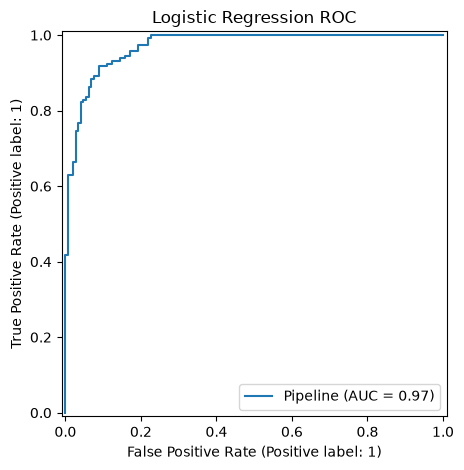

In [17]:
# ROC curve visualization
RocCurveDisplay.from_estimator(logreg, X_test_c, y_test_c)
plt.title("Logistic Regression ROC")
plt.tight_layout()
plt.show()


In [18]:
# Changed exactly two parameters: C and class_weight.
logreg_tuned = Pipeline(steps=[
    ("preprocess", preprocess_scaled),
    ("model", LogisticRegression(
        C=0.3,
        penalty="l2",
        solver="lbfgs",
        max_iter=10_000,
        class_weight="balanced",
        random_state=SEED,
    ))
])

logreg_tuned.fit(X_train_c, y_train_c)
proba_tuned = logreg_tuned.predict_proba(X_test_c)[:, 1]
pred_tuned = (proba_tuned >= 0.5).astype(int)

print("Confusion matrix (tuned):\n", confusion_matrix(y_test_c, pred_tuned))
print("\nClassification report (tuned):\n", classification_report(y_test_c, pred_tuned, digits=3))
print("ROC AUC (tuned):", roc_auc_score(y_test_c, proba_tuned))

Confusion matrix (tuned):
 [[134  12]
 [ 18 128]]

Classification report (tuned):
               precision    recall  f1-score   support

           0      0.882     0.918     0.899       146
           1      0.914     0.877     0.895       146

    accuracy                          0.897       292
   macro avg      0.898     0.897     0.897       292
weighted avg      0.898     0.897     0.897       292

ROC AUC (tuned): 0.9710546068680803


C:\Users\giova\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


### Execution interpretation questions
1. If AUC improves but confusion matrix at 0.5 worsens, how can both be true?       
AUC measures how well the model ranks positive observations above negative observations across many possible thresholds. The confusion matrix at 0.5 evaluates the model using only one specific threshold. Therefore, a model can have better overall ranking performance while having worse predictions at the particular 0.5 threshold.

2. What does a positive coefficient mean in logistic regression?        
A positive coefficient means that, holding the other features constant, an increase in that feature is associated with higher log-odds of belonging to the positive class. For a numeric feature, the direction is positive. For a one-hot encoded categorical feature, the coefficient is interpreted relative to the reference encoded categories.

3. ML Systems: what would you monitor weekly for this classifier?       
I would monitor prediction volume, predicted probability distributions, positive prediction rates, input feature drift, missingness, and categorical-value frequencies. When actual labels become available, I would also monitor AUC, precision, recall, false-positive rates, false-negative rates, and performance across important groups.

## Step 9 — Threshold tuning + ML systems reflection

### Coding questions
1. In a “target high-probability customers” scenario, which is usually more important: precision or recall? Why?        
It depends on the business cost of false positives versus false negatives. If contacting a customer is expensive or intrusive, precision may be more important because we want a high percentage of targeted customers to actually be positive cases. If missing a valuable customer is more costly, recall may be more important. The threshold should therefore be chosen based on the operational cost of each type of error.

2. What failure mode occurs if you tune thresholds on the test set?     
Tuning the threshold directly on the test set causes the test data to influence the decision-making process. This makes the test set no longer an unbiased final evaluation set. The reported performance can become overly optimistic because the threshold was selected based on the test results.

### Function/class selection and parameter exploration
- Use a confusion matrix at different thresholds; optionally `precision_recall_curve`.
- Explain how threshold choice maps to error costs and operational constraints.

In [19]:
# Threshold sweep (no refit)
thresholds = [0.2, 0.35, 0.5, 0.65, 0.8]
rows = []
for t in thresholds:
    pred_t = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_c, pred_t).ravel()
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    rows.append({"threshold": t, "precision": precision, "recall": recall, "tp": tp, "fp": fp, "tn": tn, "fn": fn})

threshold_table = pd.DataFrame(rows)
threshold_table


,threshold,precision,recall,tp,fp,tn,fn
0,0.200,0.807,1.000,146,35,111,0
1,0.350,0.857,0.945,138,23,123,8
2,0.500,0.921,0.884,129,11,135,17
3,0.650,0.938,0.836,122,8,138,24
4,0.800,0.950,0.781,114,6,140,32


In [20]:
# Objective: pick the highest recall threshold subject to precision >= 0.80.
threshold_table = pd.DataFrame(rows)
valid = threshold_table[threshold_table["precision"] >= 0.80]

if not valid.empty:
    DEPLOY_THRESHOLD = float(valid.sort_values(["recall", "threshold"], ascending=[False, True]).iloc[0]["threshold"])
else:
    # Fallback when no threshold meets the precision constraint.
    DEPLOY_THRESHOLD = 0.5

print("Chosen threshold:", DEPLOY_THRESHOLD)
threshold_table

Chosen threshold: 0.2


,threshold,precision,recall,tp,fp,tn,fn
0,0.200,0.807,1.000,146,35,111,0
1,0.350,0.857,0.945,138,23,123,8
2,0.500,0.921,0.884,129,11,135,17
3,0.650,0.938,0.836,122,8,138,24
4,0.800,0.950,0.781,114,6,140,32


### Think like an ML Systems engineer
- List 3 things you would log per prediction for regression and for classification.     
For regression, I would log the model version, prediction value, and timestamp or prediction ID. I would also log important input-data quality information when appropriate. For classification, I would log the model version, predicted probability, and final predicted class or decision. The prediction timestamp and threshold version should also be recorded so that the decision can be reproduced later.

- Identify 2 drift checks (one numeric, one categorical).       
For a numeric feature, I would monitor changes in its distribution using a method such as a Kolmogorov-Smirnov test or PSI. For a categorical feature, I would monitor changes in category frequencies and the appearance of new categories.

- Identify 1 leakage risk and how the pipeline design avoids it.        
One leakage risk is calculating imputation or scaling statistics using the entire dataset before splitting into training and test sets. The pipeline avoids this by fitting the preprocessing steps on the training data and then applying the learned transformations to the test data. This keeps information from the test set from influencing the training process.

**End of Lab**